# Pillar 1 — Commercial lending opportunity (V2)

Scores all 387 U.S. MSAs on how much **commercial lending (C&I and CRE)** a bank like BankUnited could originate there. V2 drops CRA small-business loans, which are under $1M and mostly card lending, so they don't describe BankUnited's middle-market and CRE book.

**How to use**
1. Edit **`WEIGHTS`** in section 2 (and the settings below it), then *Run All*. Weights don't have to sum to 100%; they're rescaled.
2. Section 3 documents every metric: what it is, why it matters, where it comes from and whether the data exists.
3. Sections 6–8 show the scores, BankUnited's markets, a breakdown for one MSA, and diagnostics.

**Data:** only `data/processed/` (`msa_year`, `bank_msa_year`, `bank_quarter`). Nothing is downloaded. Metrics the V2 design calls for but that aren't in `data/processed` are marked **not available** and skipped; section 4 lists them.

**Output:** `outputs/pillar_scores/pillar1_scores.csv` and `pillar1_run.json`.

## 1. Setup

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def find_repo_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "msa_year.parquet").exists():
            return p
    raise FileNotFoundError("Run this notebook from inside the repo: data/processed/msa_year.parquet not found.")


ROOT = find_repo_root()
PROCESSED = ROOT / "data" / "processed"
msa_year = pd.read_parquet(PROCESSED / "msa_year.parquet")
bank_msa_year = pd.read_parquet(PROCESSED / "bank_msa_year.parquet")
bank_quarter = pd.read_parquet(PROCESSED / "bank_quarter.parquet")
bank_quarter["quarter_end"] = pd.to_datetime(bank_quarter["quarter_end"])

# Universe: the 387 metropolitan statistical areas in the 50 states and DC (Puerto Rico excluded),
# the same universe as Pillar 4.
universe = (msa_year.loc[~msa_year.cbsa_title.str.endswith(", PR"), ["cbsa_code", "cbsa_title"]]
            .drop_duplicates().sort_values("cbsa_code").set_index("cbsa_code"))
CBSAS = list(universe.index)
TITLE = universe.cbsa_title.to_dict()
N_MSA = len(CBSAS)
print(f"repo: {ROOT.name}")
print(f"msa_year {msa_year.shape}, bank_msa_year {bank_msa_year.shape}, bank_quarter {bank_quarter.shape}")
print(f"universe: {N_MSA} MSAs")

repo: bankunited-market-expansion-main
msa_year (3930, 56), bank_msa_year (331879, 21), bank_quarter (240330, 62)
universe: 387 MSAs


In [ ]:
def wide(col):
    """msa_year column as a CBSA x year table, restricted to the universe."""
    return msa_year.pivot(index="cbsa_code", columns="year", values=col).reindex(CBSAS)


def r12(s):
    return s.astype(float).round(12)


def cagr(start, end, years):
    """Compound annual growth; blank unless both ends exist and the start is positive."""
    ok = start.notna() & end.notna() & (start > 0)
    return r12((end / start) ** (1 / years) - 1).where(ok)


def ratio(num, den):
    """num / den; blank unless both exist and den is positive."""
    ok = num.notna() & den.notna() & (den > 0)
    return r12(num / den).where(ok)


def call(quarter_end):
    """Call Report values for one quarter, indexed by RSSD ID."""
    q = bank_quarter[bank_quarter.quarter_end == pd.Timestamp(quarter_end)].set_index("rssd_id")
    return q

def oriented_percentiles(metrics, directions):
    """Average-rank percentiles (0-100) among MSAs that have the metric; higher always = more attractive.
    Same rule as the Pillar 4 V2 workbook: 100 x (average oriented rank - 1) / (valid count - 1)."""
    P = pd.DataFrame(index=metrics.index)
    for col in metrics.columns:
        v = metrics[col] if directions[col] == "Higher" else -metrics[col]
        n = v.notna().sum()
        P[col] = 100 * (v.rank(method="average") - 1) / (n - 1) if n > 1 else np.nan
    return P


def score(metrics, directions, weights):
    """Available-data score (weights renormalized over the metrics an MSA has) and complete score
    (only when every metric is present). Ranks are among complete MSAs only."""
    w = pd.Series(weights, dtype=float)[list(metrics.columns)]
    P = oriented_percentiles(metrics, directions)
    have = P.notna()
    avail_w = have.mul(w, axis=1).sum(axis=1)
    available = P.fillna(0).mul(w, axis=1).sum(axis=1) / avail_w.where(avail_w > 0)
    complete = available.where(have.all(axis=1))
    out = pd.DataFrame({
        "msa": pd.Series(TITLE),
        "complete_score": complete,
        "rank": complete.rank(ascending=False, method="min"),
        "available_score": available,
        "valid_metrics": have.sum(axis=1),
        "weight_coverage": avail_w,
        "missing_metrics": have.apply(lambda r: ", ".join(c for c in r.index if not r[c]), axis=1),
    })
    contrib = P.mul(w, axis=1)            # weighted points per metric (sum = complete score)
    return out, P, contrib


def weight_rank_ranges(metrics, directions, weights, shock=0.25):
    """Best and worst complete rank when each weight alone moves +/- shock (then renormalized)."""
    base, _, _ = score(metrics, directions, weights)
    ranks = [base["rank"]]
    for k in weights:
        for s in (-shock, shock):
            w = dict(weights)
            w[k] = weights[k] * (1 + s)
            tot = sum(w.values())
            w = {kk: vv / tot for kk, vv in w.items()}
            ranks.append(score(metrics, directions, w)[0]["rank"])
    R = pd.concat(ranks, axis=1)
    return pd.DataFrame({"best_rank": R.min(axis=1), "worst_rank": R.max(axis=1)})


def check_weights(weights, registry):
    w = pd.Series(weights, dtype=float)
    unknown = sorted(set(w.index) - set(registry.index))
    assert not unknown, f"weights for unknown metrics: {unknown}"
    assert (w >= 0).all(), "weights must be zero or positive"
    unavailable = [k for k in w.index if registry.loc[k, "status"] == "not available" and w[k] > 0]
    used = w[[k for k in w.index if registry.loc[k, "status"] != "not available" and w[k] > 0]]
    assert len(used) > 0, "no weighted metric is available"
    eff = used / used.sum()
    if abs(w.sum() - 1) > 1e-9:
        print(f"Note: entered weights sum to {w.sum():.4f}; they are rescaled to 100%.")
    if unavailable:
        print("Weighted but NOT available in data/processed, so left out and the rest rescaled:",
              ", ".join(unavailable))
    return eff

def show_rank_table(results, metrics, n=25):
    cols = ["msa", "complete_score", "rank", "available_score", "valid_metrics"]
    t = results.sort_values(["complete_score", "available_score"], ascending=False)[cols].head(n)
    return t.round(2)

## 2. Weights and settings — edit here

Baseline = the **reliability weights** adopted on 2026-10-20: size (middle-market establishments) 25%, its growth 15%, local-lender metrics 5% each because many MSAs have only a few small local banks, everything else 10%. The two multifamily metrics keep their design weight but are skipped until the data exists, so the remaining weights are rescaled (see section 3, *effective weight*). **Rescaling raises the size metric from 25% to 31%**; if you'd rather keep CRE at 30%, move the multifamily 20% onto `cre_payroll_growth` or `local_cre_growth` by hand.

In [ ]:
WEIGHTS = {
    # Bank-reported commercial lending
    "local_ci_growth":        0.05,
    "local_cre_growth":       0.05,
    "local_loans_to_deposits": 0.05,
    "allocated_loan_growth":  0.10,
    # Middle-market borrower base
    "mm_establishments":      0.25,
    "mm_growth":              0.15,
    "mm_share":               0.05,
    # CRE lending
    "multifamily_lending":    0.10,   # not available in data/processed (HMDA) — skipped
    "multifamily_permits":    0.10,   # not available in data/processed (Census BPS) — skipped
    "cre_payroll_growth":     0.10,
}

SETTINGS = {
    "local_lender_threshold": 0.50,   # a bank is a local lender in an MSA holding >= this share of its domestic deposits
    "growth_cap": 0.25,               # max annual same-bank loan growth counted (so acquisitions don't read as demand)
    "base_quarter": "2019-06-30",     # Call Report / SOD start
    "end_quarter": "2024-06-30",      # Call Report / SOD end (SOD June 30 survey)
    "cbp_start": 2018, "cbp_end": 2023,
    "exclude_home_banking_offices": True,   # treat home-banking-office deposits like main-office bookings (10/26 decision)
}
EXAMPLE_CBSA = "16740"   # Charlotte, the pilot
PILLAR_TAG = "pillar1"

## 3. Metric dictionary

| # | Metric | Group | Definition | Why it matters for BankUnited | Status |
|---|---|---|---|---|---|
| 1 | Local-lender C&I growth | Bank-reported lending | 2019–24 CAGR of C&I loans at *local lenders* (banks with ≥ 50% of domestic deposits in the MSA), same banks both years, each bank capped at 25%/yr | A local bank's loan book is the local market's loan book, so its C&I growth is a direct read of commercial loan demand there. | Available |
| 2 | Local-lender CRE growth | Bank-reported lending | Same, for CRE (construction + multifamily + nonfarm nonresidential) | Same logic for the CRE half of BankUnited's book. | Available |
| 3 | Local-lender commercial loans / deposits | Bank-reported lending | Local lenders' C&I + CRE ÷ their deposits, June 2024 | High means local funding is being put to work in commercial loans — demand is strong relative to deposits. | Available |
| 4 | Allocated commercial loan growth | Bank-reported lending | Every bank's C&I + CRE spread to MSAs by its share of deposits *not* booked at main or home-banking offices; 2019 vs 2024 CAGR | Uses all banks, including large regionals, as a cross-check; only growth is scored because the level just tracks deposits. | Available |
| 5 | Middle-market establishments | Middle-market borrowers | CBP establishments with 20–249 employees, 2023 | The pool of potential middle-market C&I clients; the pillar's only scale metric. | Available (20–249; design said 20–499) |
| 6 | Middle-market growth | Middle-market borrowers | 2018–23 CAGR of the same count | Growing middle-market bases create new relationships for a new entrant to win. | Available (20–249) |
| 7 | Middle-market share | Middle-market borrowers | 20–249 establishments ÷ all establishments, 2023 | Separates economies of mid-sized firms from ones dominated by micro-businesses. | Available (20–249) |
| 8 | Multifamily lending per capita | CRE lending | HMDA multifamily (5+ unit) originations, 2022–24 average, per resident | Actual multifamily loan volume — the closest public measure of CRE lending demand. | **Not available** |
| 9 | 5+ unit permits per 1,000 | CRE lending | Census Building Permits, units in 5+ unit buildings, 2022–24 average | Pipeline of construction and permanent multifamily financing. | **Not available** |
| 10 | Commercial real estate payroll growth | CRE lending | 2018–23 CAGR of CBP payroll in real estate (NAICS 531) + nonresidential building construction (NAICS 2362) | Growth in the people who own, lease and build commercial property is a proxy for CRE activity. | Substitute (design used NAICS 531120, not in repo) |

In [ ]:
REGISTRY = pd.DataFrame([
    # key, label, group, direction, period, source, status
    ("local_ci_growth", "Local-lender C&I growth", "Bank-reported lending", "Higher", "2019–24 CAGR", "bank_quarter + bank_msa_year", "available"),
    ("local_cre_growth", "Local-lender CRE growth", "Bank-reported lending", "Higher", "2019–24 CAGR", "bank_quarter + bank_msa_year", "available"),
    ("local_loans_to_deposits", "Local-lender commercial loans / deposits", "Bank-reported lending", "Higher", "June 2024", "bank_quarter + bank_msa_year", "available"),
    ("allocated_loan_growth", "Allocated commercial loan growth", "Bank-reported lending", "Higher", "2019–24 CAGR", "bank_quarter + bank_msa_year", "available"),
    ("mm_establishments", "Middle-market establishments (20–249)", "Middle-market borrowers", "Higher", "2023", "msa_year.cbp_establishments_20_249_count", "substitute"),
    ("mm_growth", "Middle-market establishment growth", "Middle-market borrowers", "Higher", "2018–23 CAGR", "msa_year.cbp_establishments_20_249_count", "substitute"),
    ("mm_share", "Middle-market share of establishments", "Middle-market borrowers", "Higher", "2023", "msa_year.cbp_establishments_*", "substitute"),
    ("multifamily_lending", "Multifamily lending per capita", "CRE lending", "Higher", "2022–24 avg", "HMDA — not in data/processed", "not available"),
    ("multifamily_permits", "5+ unit permits per 1,000", "CRE lending", "Higher", "2022–24 avg", "Census BPS — not in data/processed", "not available"),
    ("cre_payroll_growth", "Commercial real estate payroll growth", "CRE lending", "Higher", "2018–23 CAGR", "msa_year.cre_* (NAICS 531 + 2362)", "substitute"),
], columns=["key", "label", "group", "direction", "period", "source", "status"]).set_index("key")

EFFECTIVE = check_weights(WEIGHTS, REGISTRY)
ACTIVE = list(EFFECTIVE.index)
DIRECTIONS = REGISTRY.direction.to_dict()
REGISTRY["entered_weight"] = pd.Series(WEIGHTS)
REGISTRY["effective_weight"] = EFFECTIVE
display_reg = REGISTRY.assign(entered_weight=REGISTRY.entered_weight.map("{:.1%}".format),
                              effective_weight=REGISTRY.effective_weight.map(lambda v: "—" if pd.isna(v) else f"{v:.1%}"))
display_reg

Weighted but NOT available in data/processed, so left out and the rest rescaled: multifamily_lending, multifamily_permits


,label,group,direction,period,source,status,entered_weight,effective_weight
key,,,,,,,,
local_ci_growth,Local-lender C&I growth,Bank-reported lending,Higher,2019–24 CAGR,bank_quarter + bank_msa_year,available,5.0%,6.2%
local_cre_growth,Local-lender CRE growth,Bank-reported lending,Higher,2019–24 CAGR,bank_quarter + bank_msa_year,available,5.0%,6.2%
local_loans_to_deposits,Local-lender commercial loans / deposits,Bank-reported lending,Higher,June 2024,bank_quarter + bank_msa_year,available,5.0%,6.2%
allocated_loan_growth,Allocated commercial loan growth,Bank-reported lending,Higher,2019–24 CAGR,bank_quarter + bank_msa_year,available,10.0%,12.5%
mm_establishments,Middle-market establishments (20–249),Middle-market borrowers,Higher,2023,msa_year.cbp_establishments_20_249_count,substitute,25.0%,31.2%
mm_growth,Middle-market establishment growth,Middle-market borrowers,Higher,2018–23 CAGR,msa_year.cbp_establishments_20_249_count,substitute,15.0%,18.7%
mm_share,Middle-market share of establishments,Middle-market borrowers,Higher,2023,msa_year.cbp_establishments_*,substitute,5.0%,6.2%
multifamily_lending,Multifamily lending per capita,CRE lending,Higher,2022–24 avg,HMDA — not in data/processed,not available,10.0%,—
multifamily_permits,"5+ unit permits per 1,000",CRE lending,Higher,2022–24 avg,Census BPS — not in data/processed,not available,10.0%,—


## 4. Data availability check

In [ ]:
NEEDED = {
    "msa_year": ["cbp_establishments_count", "cbp_establishments_20_249_count", "cbp_annual_payroll_usd",
                 "cre_real_estate_payroll_usd", "cre_nonres_construction_payroll_usd", "sod_deposits_usd"],
    "bank_msa_year": ["sod_deposits_usd", "sod_main_office_deposits_usd", "sod_home_banking_office_deposits_usd"],
    "bank_quarter": ["call_ci_loans_usd", "call_construction_loans_usd", "call_multifamily_loans_usd",
                     "call_nonfarm_nonres_loans_usd", "call_domestic_deposits_usd", "call_total_deposits_usd"],
}
tables = {"msa_year": msa_year, "bank_msa_year": bank_msa_year, "bank_quarter": bank_quarter}
rows = [(t, c, c in tables[t].columns) for t, cols in NEEDED.items() for c in cols]
avail = pd.DataFrame(rows, columns=["table", "column", "present"])
assert avail.present.all(), avail[~avail.present]
have_q = set(bank_quarter.quarter_end.dt.strftime("%Y-%m-%d"))
cbp_years = set(msa_year.dropna(subset=["cbp_establishments_20_249_count"]).year)
sod_years = set(bank_msa_year.dropna(subset=["sod_deposits_usd"]).year)
checks = {f"Call Report {SETTINGS['base_quarter']}": SETTINGS["base_quarter"] in have_q,
          f"Call Report {SETTINGS['end_quarter']}": SETTINGS["end_quarter"] in have_q,
          f"SOD {SETTINGS['base_quarter'][:4]} and {SETTINGS['end_quarter'][:4]}": {int(SETTINGS["base_quarter"][:4]), int(SETTINGS["end_quarter"][:4])} <= sod_years,
          f"CBP {SETTINGS['cbp_start']} and {SETTINGS['cbp_end']}": {SETTINGS["cbp_start"], SETTINGS["cbp_end"]} <= cbp_years}
assert all(checks.values()), checks
print("All required columns and periods present:", ", ".join(checks))

NOT_AVAILABLE = pd.DataFrame([
    ("Multifamily lending per capita", "HMDA loan-level multifamily (5+ unit) originations by county", "Add an HMDA ingest (CFPB Data Browser nationwide CSV, total_units 5+)"),
    ("5+ unit permits per 1,000", "Census Building Permits Survey, county annual, 5+ unit buildings", "Add a BPS ingest (www2.census.gov/econ/bps/County/coYYYYa.txt)"),
    ("Commercial real estate payroll growth", "CBP NAICS 531120 (lessors of nonresidential buildings)", "Using NAICS 531 (all real estate, includes residential lessors) until 531120 is ingested"),
    ("Middle-market establishments (3 metrics)", "CBP establishments with 250–499 employees", "Using 20–249; add N250_499 to the CBP ingest for the 20–499 definition"),
], columns=["metric", "missing data", "what to do"])
NOT_AVAILABLE

All required columns and periods present: Call Report 2019-06-30, Call Report 2024-06-30, SOD 2019 and 2024, CBP 2018 and 2023


,metric,missing data,what to do
0,Multifamily lending per capita,HMDA loan-level multifamily (5+ unit) originations by county,"Add an HMDA ingest (CFPB Data Browser nationwide CSV, total_units 5+)"
1,"5+ unit permits per 1,000","Census Building Permits Survey, county annual, 5+ unit buildings",Add a BPS ingest (www2.census.gov/econ/bps/County/coYYYYa.txt)
2,Commercial real estate payroll growth,CBP NAICS 531120 (lessors of nonresidential buildings),"Using NAICS 531 (all real estate, includes residential lessors) until 531120 is ingested"
3,Middle-market establishments (3 metrics),CBP establishments with 250–499 employees,Using 20–249; add N250_499 to the CBP ingest for the 20–499 definition


## 5. Build the metrics

### 5a. Bank-reported commercial lending
Local lenders: a bank is local to an MSA when its SOD deposits there are at least `local_lender_threshold` of its Call Report domestic deposits (June 2024). For those banks the Call Report loan book is mostly the local market's loans. Growth is same-bank (same RSSD ID in 2019), each bank capped at `growth_cap` a year so an acquisition doesn't look like demand.

In [ ]:
base_q, end_q = SETTINGS["base_quarter"], SETTINGS["end_quarter"]
y0, y1 = int(base_q[:4]), int(end_q[:4])


def loan_book(q):
    c = call(q)
    return pd.DataFrame({
        "ci": c.call_ci_loans_usd,
        "cre": c.call_construction_loans_usd.fillna(0) + c.call_multifamily_loans_usd.fillna(0)
               + c.call_nonfarm_nonres_loans_usd.fillna(0),
        "domestic_deposits": c.call_domestic_deposits_usd,
        "total_deposits": c.call_total_deposits_usd,
    })


book0, book1 = loan_book(base_q), loan_book(end_q)

# --- local lenders (June 2024)
s = bank_msa_year[(bank_msa_year.year == y1) & bank_msa_year.sod_deposits_usd.notna()].join(book1, on="rssd_id")
s = s[s.domestic_deposits > 0].copy()
s["share_in_msa"] = np.minimum(1, s.sod_deposits_usd / s.domestic_deposits)
local = s[(s.share_in_msa >= SETTINGS["local_lender_threshold"]) & s.cbsa_code.isin(CBSAS)].copy()
local["ci0"] = local.rssd_id.map(book0.ci)
local["cre0"] = local.rssd_id.map(book0.cre)
cap = (1 + SETTINGS["growth_cap"]) ** (y1 - y0)
for k in ("ci", "cre"):
    ok = local[f"{k}0"] > 0
    local[f"{k}_base"] = np.where(ok, local[f"{k}0"], 0)
    local[f"{k}_end_capped"] = np.where(ok, np.minimum(local[k].fillna(0), local[f"{k}0"] * cap), 0)
local["commercial"] = local.ci.fillna(0) + local.cre.fillna(0)
g = local.groupby("cbsa_code")
L = pd.DataFrame({c: g[c].sum() for c in ["ci_base", "ci_end_capped", "cre_base", "cre_end_capped",
                                         "commercial", "total_deposits"]}).reindex(CBSAS).fillna(0)
L["local_lenders"] = g.size().reindex(CBSAS).fillna(0).astype(int)


def pos_cagr(a, b, years):
    return r12((b / a) ** (1 / years) - 1).where((a > 0) & (b > 0))


metrics = pd.DataFrame(index=CBSAS)
metrics["local_ci_growth"] = pos_cagr(L.ci_base, L.ci_end_capped, y1 - y0)
metrics["local_cre_growth"] = pos_cagr(L.cre_base, L.cre_end_capped, y1 - y0)
metrics["local_loans_to_deposits"] = r12(L.commercial / L.total_deposits).where(L.total_deposits > 0)
print(f"Local lenders: {len(local)} bank-MSA rows; {int((L.local_lenders > 0).sum())} of {N_MSA} MSAs have at least one.")

Local lenders: 2236 bank-MSA rows; 332 of 387 MSAs have at least one.


In [ ]:
# --- deposit-share allocation of every bank's C&I + CRE (independent snapshots, so in-market mergers net out)
def allocated(year, book):
    a = bank_msa_year[(bank_msa_year.year == year) & bank_msa_year.sod_deposits_usd.notna()].copy()
    booked = a.sod_main_office_deposits_usd.fillna(0)
    if SETTINGS["exclude_home_banking_offices"]:
        booked = booked + a.sod_home_banking_office_deposits_usd.fillna(0)
    a["booked"] = booked
    a["booked_total"] = a.groupby("rssd_id").booked.transform("sum")
    a = a.join(book, on="rssd_id")
    den = a.domestic_deposits - a.booked_total
    a["share"] = np.where(den > 0, np.clip((a.sod_deposits_usd - a.booked) / den, 0, 1), 0)
    a["alloc"] = a.share * (a.ci.fillna(0) + a.cre.fillna(0))
    return a.groupby("cbsa_code").alloc.sum().reindex(CBSAS).fillna(0)


alloc0, alloc1 = allocated(y0, book0), allocated(y1, book1)
metrics["allocated_loan_growth"] = pos_cagr(alloc0, alloc1, y1 - y0)

### 5b. Middle-market borrower base and 5c. CRE lending

In [ ]:
c0, c1 = SETTINGS["cbp_start"], SETTINGS["cbp_end"]
mm = wide("cbp_establishments_20_249_count")
est = wide("cbp_establishments_count")
metrics["mm_establishments"] = mm[c1]
metrics["mm_growth"] = cagr(mm[c0], mm[c1], c1 - c0)
metrics["mm_share"] = ratio(mm[c1], est[c1])

cre_pay = wide("cre_real_estate_payroll_usd") + wide("cre_nonres_construction_payroll_usd")
metrics["cre_payroll_growth"] = cagr(cre_pay[c0], cre_pay[c1], c1 - c0)

# Metrics that are not in data/processed stay as empty columns so the table shows the full design.
for k in REGISTRY.index[REGISTRY.status == "not available"]:
    metrics[k] = np.nan
metrics = metrics[list(REGISTRY.index)]

coverage = pd.DataFrame({"label": REGISTRY.label, "status": REGISTRY.status,
                         "MSAs with a value": metrics.notna().sum(), "median": metrics.median().round(4)})
coverage

,label,status,MSAs with a value,median
local_ci_growth,Local-lender C&I growth,available,326,0.0616
local_cre_growth,Local-lender CRE growth,available,330,0.1000
local_loans_to_deposits,Local-lender commercial loans / deposits,available,332,0.4534
allocated_loan_growth,Allocated commercial loan growth,available,382,0.0506
mm_establishments,Middle-market establishments (20–249),substitute,387,833.0000
mm_growth,Middle-market establishment growth,substitute,382,0.0062
mm_share,Middle-market share of establishments,substitute,387,0.1482
multifamily_lending,Multifamily lending per capita,not available,0,NaN
multifamily_permits,"5+ unit permits per 1,000",not available,0,NaN
cre_payroll_growth,Commercial real estate payroll growth,substitute,381,0.0628


In [ ]:
FMT_PCT = lambda v: "—" if pd.isna(v) else f"{v:.2%}"
FMT_NUM = lambda v: "—" if pd.isna(v) else f"{v:,.0f}"
FORMAT = {k: FMT_PCT for k in REGISTRY.index}
FORMAT["mm_establishments"] = FMT_NUM
# All raw metrics for every MSA (one row per MSA); sort or filter as needed.
metrics.join(pd.Series(TITLE, name="msa")).set_index("msa", append=True).loc[:, ACTIVE].head(10)

,,local_ci_growth,local_cre_growth,local_loans_to_deposits,allocated_loan_growth,mm_establishments,mm_growth,mm_share,cre_payroll_growth
,msa,,,,,,,,
10180,"Abilene, TX",0.0434,-0.0232,0.2968,0.0699,577.0000,0.0039,0.1383,0.0150
10420,"Akron, OH",0.0741,0.0570,0.4376,0.0219,"2,795.0000",-0.0004,0.1708,0.0268
10500,"Albany, GA",0.0995,0.0558,0.3754,0.0525,468.0000,0.0052,0.1503,0.0406
10540,"Albany, OR",NaN,NaN,NaN,0.0505,359.0000,0.0028,0.1261,0.0654
10580,"Albany-Schenectady-Troy, NY",-0.0453,0.0758,0.2194,-0.0142,"3,113.0000",-0.0044,0.1453,0.0329
10740,"Albuquerque, NM",0.1658,0.1375,0.8645,0.0528,"3,029.0000",0.0065,0.1558,0.0756
10780,"Alexandria, LA",0.0450,0.0916,0.4512,0.0739,463.0000,0.0135,0.1374,0.0114
10900,"Allentown-Bethlehem-Easton, PA-NJ",0.0567,0.0473,0.3927,0.0371,"2,891.0000",0.0024,0.1546,0.0410
11020,"Altoona, PA",0.0181,0.0303,0.3272,0.0253,542.0000,0.0126,0.1705,0.0637


## 6. Score

Each metric becomes a percentile (0–100) among the MSAs that have it, oriented so higher is always more attractive. The **complete score** is the weighted average of the percentiles and needs every weighted metric. The **available-data score** renormalizes the weights over the metrics an MSA has, so MSAs with gaps still get a provisional number. Ranks are among complete MSAs only. This is the same method as the Pillar 4 V2 workbook.

In [ ]:
results, P, contrib = score(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict())
n_complete = int(results["rank"].notna().sum())
print(f"{n_complete} complete, {N_MSA - n_complete} partial")
print(results.loc[results["rank"].isna(), "missing_metrics"].value_counts().head(5).to_string())

321 complete, 66 partial
missing_metrics
local_ci_growth, local_cre_growth, local_loans_to_deposits                        54
allocated_loan_growth, mm_growth, cre_payroll_growth                               5
local_ci_growth                                                                    4
local_ci_growth, local_cre_growth                                                  2
local_ci_growth, local_cre_growth, local_loans_to_deposits, cre_payroll_growth     1


In [ ]:
show_rank_table(results, metrics, n=25)

,msa,complete_score,rank,available_score,valid_metrics
26900,"Indianapolis-Carmel-Greenwood, IN",86.7800,1.0000,86.7800,8
12420,"Austin-Round Rock-San Marcos, TX",83.3100,2.0000,83.3100,8
48900,"Wilmington, NC",82.8300,3.0000,82.8300,8
39580,"Raleigh-Cary, NC",82.8000,4.0000,82.8000,8
22220,"Fayetteville-Springdale-Rogers, AR",82.4500,5.0000,82.4500,8
38060,"Phoenix-Mesa-Chandler, AZ",80.8100,6.0000,80.8100,8
14260,"Boise City, ID",79.9100,7.0000,79.9100,8
28940,"Knoxville, TN",79.3200,8.0000,79.3200,8
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",78.9900,9.0000,78.9900,8
18140,"Columbus, OH",77.5400,10.0000,77.5400,8


## 7. BankUnited's markets and an example MSA

In [ ]:
# BankUnited's markets. Branch markets come from the data (msa_year.bankunited_sod_offices_count, June 2024).
# Markets it serves from offices without branches are not visible in SOD; they come from src/bankunited.py
# (Atlanta office opened 2022-04-07) and the project work order (Charlotte entry July 2025; Houston office).
bu_branch = msa_year[(msa_year.year == 2024) & (msa_year.bankunited_sod_offices_count > 0)].cbsa_code.tolist()
BU_OFFICE_ONLY = {"12060": "Atlanta office", "16740": "Charlotte (entered Jul 2025)", "26420": "Houston office"}
bu_markets = pd.DataFrame({"cbsa_code": bu_branch + [c for c in BU_OFFICE_ONLY if c not in bu_branch]})
bu_markets["presence"] = ["SOD branch" if c in bu_branch else BU_OFFICE_ONLY[c] for c in bu_markets.cbsa_code]
bu_markets = bu_markets.set_index("cbsa_code").join(results[["msa", "complete_score", "rank", "available_score"]])
bu_markets.sort_values("rank").round(2)

,presence,msa,complete_score,rank,available_score
cbsa_code,,,,,
15980,SOD branch,"Cape Coral-Fort Myers, FL",74.2400,15.0000,74.2400
12060,Atlanta office,"Atlanta-Sandy Springs-Roswell, GA",73.5700,19.0000,73.5700
26420,Houston office,"Houston-Pasadena-The Woodlands, TX",71.8000,23.0000,71.8000
19100,SOD branch,"Dallas-Fort Worth-Arlington, TX",71.6900,25.0000,71.6900
36740,SOD branch,"Orlando-Kissimmee-Sanford, FL",70.0000,33.0000,70.0000
16740,Charlotte (entered Jul 2025),"Charlotte-Concord-Gastonia, NC-SC",69.9900,34.0000,69.9900
35840,SOD branch,"North Port-Bradenton-Sarasota, FL",66.4700,47.0000,66.4700
33100,SOD branch,"Miami-Fort Lauderdale-West Palm Beach, FL",63.9400,64.0000,63.9400
45300,SOD branch,"Tampa-St. Petersburg-Clearwater, FL",62.7900,78.0000,62.7900


Charlotte-Concord-Gastonia, NC-SC: complete score 69.99, rank 34 of 321


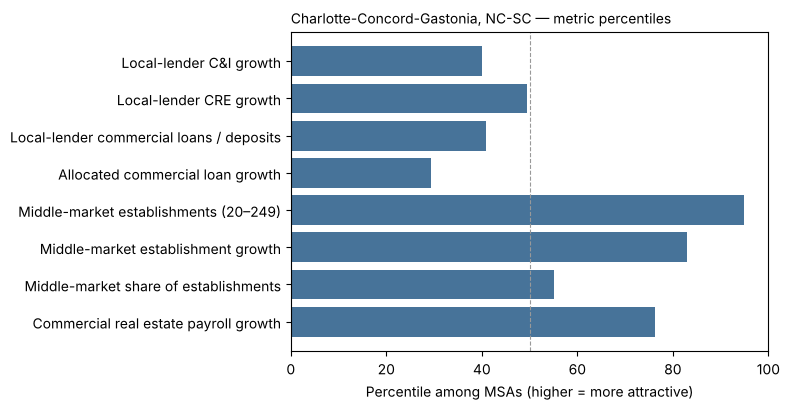

,metric,raw value,percentile,weight,points
local_ci_growth,Local-lender C&I growth,5.10%,40.0000,6.2%,2.5000
local_cre_growth,Local-lender CRE growth,9.95%,49.5000,6.2%,3.1000
local_loans_to_deposits,Local-lender commercial loans / deposits,41.98%,40.8000,6.2%,2.5500
allocated_loan_growth,Allocated commercial loan growth,3.52%,29.4000,12.5%,3.6700
mm_establishments,Middle-market establishments (20–249),"10,737",94.8000,31.2%,29.6300
mm_growth,Middle-market establishment growth,1.81%,82.9000,18.7%,15.5500
mm_share,Middle-market share of establishments,15.04%,55.2000,6.2%,3.4500
cre_payroll_growth,Commercial real estate payroll growth,9.14%,76.3000,12.5%,9.5400


In [ ]:
ex = EXAMPLE_CBSA
breakdown = pd.DataFrame({
    "metric": REGISTRY.loc[ACTIVE, "label"],
    "raw value": [FORMAT[k](metrics.loc[ex, k]) for k in ACTIVE],
    "percentile": P.loc[ex, ACTIVE].round(1),
    "weight": [f"{EFFECTIVE[k]:.1%}" for k in ACTIVE],
    "points": contrib.loc[ex, ACTIVE].round(2),
})
print(f"{TITLE[ex]}: complete score {results.loc[ex, 'complete_score']:.2f}, rank {results.loc[ex, 'rank']:.0f} of "
      f"{int(results['rank'].notna().sum())}")
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(ACTIVE) + 1))
    b = breakdown.iloc[::-1]
    ax.barh(b["metric"], b["percentile"], color="#477399")
    ax.axvline(50, color="#999", lw=0.8, ls="--")
    ax.set_xlim(0, 100); ax.set_xlabel("Percentile among MSAs (higher = more attractive)")
    ax.set_title(f"{TITLE[ex]} — metric percentiles", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed; table only.")
breakdown

## 8. Diagnostics

In [ ]:
# Redundancy check: Spearman correlation between metrics. Pairs above ~0.8 measure nearly the same thing,
# so together they carry double weight.
corr = metrics[ACTIVE].corr(method="spearman").round(2)
high = [(a, b, corr.loc[a, b]) for i, a in enumerate(ACTIVE) for b in ACTIVE[i + 1:] if abs(corr.loc[a, b]) >= 0.8]
print("Highly correlated pairs (|rho| >= 0.8):", high or "none")
corr

Highly correlated pairs (|rho| >= 0.8): none


,local_ci_growth,local_cre_growth,local_loans_to_deposits,allocated_loan_growth,mm_establishments,mm_growth,mm_share,cre_payroll_growth
local_ci_growth,1.0000,0.3700,0.1300,0.0700,0.1000,0.1600,0.0400,0.0100
local_cre_growth,0.3700,1.0000,0.3400,0.1600,0.1000,0.0500,0.0900,0.0100
local_loans_to_deposits,0.1300,0.3400,1.0000,0.0800,0.1000,0.0100,0.0900,-0.0400
allocated_loan_growth,0.0700,0.1600,0.0800,1.0000,-0.0600,0.2100,0.0600,0.0900
mm_establishments,0.1000,0.1000,0.1000,-0.0600,1.0000,0.1500,0.1300,0.1000
mm_growth,0.1600,0.0500,0.0100,0.2100,0.1500,1.0000,-0.1900,0.3400
mm_share,0.0400,0.0900,0.0900,0.0600,0.1300,-0.1900,1.0000,-0.1300
cre_payroll_growth,0.0100,0.0100,-0.0400,0.0900,0.1000,0.3400,-0.1300,1.0000


In [ ]:
# Weight sensitivity: best and worst rank when each weight alone moves +/-25% (as in the workbook).
rr = weight_rank_ranges(metrics[ACTIVE], DIRECTIONS, EFFECTIVE.to_dict(), shock=0.25)
top = results.sort_values("rank").head(25).join(rr)
top[["msa", "complete_score", "rank", "best_rank", "worst_rank"]].round(2)

,msa,complete_score,rank,best_rank,worst_rank
26900,"Indianapolis-Carmel-Greenwood, IN",86.7800,1.0000,1.0000,1.0000
12420,"Austin-Round Rock-San Marcos, TX",83.3100,2.0000,2.0000,4.0000
48900,"Wilmington, NC",82.8300,3.0000,2.0000,5.0000
39580,"Raleigh-Cary, NC",82.8000,4.0000,2.0000,5.0000
22220,"Fayetteville-Springdale-Rogers, AR",82.4500,5.0000,3.0000,5.0000
38060,"Phoenix-Mesa-Chandler, AZ",80.8100,6.0000,6.0000,7.0000
14260,"Boise City, ID",79.9100,7.0000,6.0000,9.0000
28940,"Knoxville, TN",79.3200,8.0000,7.0000,9.0000
34980,"Nashville-Davidson--Murfreesboro--Franklin, TN",78.9900,9.0000,8.0000,9.0000
18140,"Columbus, OH",77.5400,10.0000,10.0000,11.0000


## 9. Export

In [ ]:
out_dir = ROOT / "outputs" / "pillar_scores"
out_dir.mkdir(parents=True, exist_ok=True)
table = (results.join(metrics[ACTIVE].add_prefix("raw_")).join(P[ACTIVE].add_prefix("pct_"))
         .sort_values(["complete_score", "available_score"], ascending=False))
table.rename_axis("cbsa_code").to_csv(out_dir / f"{PILLAR_TAG}_scores.csv")
run = {"pillar": PILLAR_TAG, "run_date": str(pd.Timestamp.today().date()), "effective_weights": EFFECTIVE.round(6).to_dict(),
       "entered_weights": WEIGHTS, "settings": SETTINGS, "complete_msas": int(results["rank"].notna().sum()),
       "not_available": REGISTRY.index[REGISTRY.status == "not available"].tolist()}
(out_dir / f"{PILLAR_TAG}_run.json").write_text(json.dumps(run, indent=2))
print("wrote", (out_dir / f"{PILLAR_TAG}_scores.csv").relative_to(ROOT), "and", (out_dir / f"{PILLAR_TAG}_run.json").relative_to(ROOT))

wrote outputs/pillar_scores/pillar1_scores.csv and outputs/pillar_scores/pillar1_run.json


## Notes and limits
- **Call Report loans are bank-wide.** Local lenders are mostly community banks, so their growth reads local demand but not BankUnited-size relationships. MSAs with no local lender at the threshold (mostly California and Arizona metros) get partial scores; lowering `local_lender_threshold` to 0.40 adds coverage.
- **Allocation follows branches.** Lending without branches, BankUnited's own mode in Charlotte and Atlanta, is invisible to it; that's why only its growth is scored.
- **Connecticut** has no 2018/2019 base years in CBP and SOD (old county codes), so its five MSAs are partial.
- **Weights are judgment, not fitted.** Refit them on the 2016–21 peer-entry backtest before treating ranks as final.